<a href="https://colab.research.google.com/github/AlbertPuentes/Maching_JOBs_y_HVs_4/blob/main/Jobs_Matching_HVs_4.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Modelo de Matching Oferta Laboral HVs



In [2]:
import os
import re
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch
import torch.nn as nn
from IPython.display import display, HTML
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

warnings.filterwarnings('ignore')

SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)

df_ofertas = pd.read_csv('Ofertas_laborales.csv').fillna('')
df_hvs = pd.read_csv('Test_Hvs.csv').fillna('')

print(f"Ofertas laborales cargadas: {df_ofertas.shape[0]:,} registros | {df_ofertas.shape[1]} columnas")
print(f"Hojas de vida cargadas:     {df_hvs.shape[0]:,} registros | {df_hvs.shape[1]} columnas")


Ofertas laborales cargadas: 4,596 registros | 9 columnas
Hojas de vida cargadas:     300 registros | 12 columnas


## 1. Preprocesamiento NLP y Vectorización Ponderada (Unigramas + Bigramas)


In [3]:
def clean_text_v4(text):
    text = re.sub(r'[^\w\s\.\,\-\+\#]', ' ', str(text))
    text = re.sub(r'\s+', ' ', text)
    return text.strip().lower()

df_ofertas['text_corpus'] = (
    (df_ofertas['job_title'] + ' ') * 3 +
    (df_ofertas['job_skill_set'] + ' ') * 2 +
    df_ofertas['job_description']
).apply(clean_text_v4)

df_hvs['text_corpus'] = (
    (df_hvs['Título_Profesional'] + ' ') * 3 +
    (df_hvs['Habilidades_Técnicas'] + ' ') * 2 +
    df_hvs['Habilidades_Blandas'] + ' ' +
    df_hvs['Experiencia_Empresa_Cargo'] + ' ' +
    df_hvs['Formación_Títulos']
).apply(clean_text_v4)

all_texts = df_ofertas['text_corpus'].tolist() + df_hvs['text_corpus'].tolist()

vectorizer = TfidfVectorizer(
    max_features=3500,
    stop_words='english',
    ngram_range=(1, 2),
    sublinear_tf=True
)
X_all = vectorizer.fit_transform(all_texts).toarray()
X_tensor = torch.tensor(X_all, dtype=torch.float32)

title_vec = TfidfVectorizer(ngram_range=(1, 2), sublinear_tf=True, stop_words='english')
T_all = title_vec.fit_transform(
    df_ofertas['job_title'].apply(clean_text_v4).tolist() +
    df_hvs['Título_Profesional'].apply(clean_text_v4).tolist()
)
num_ofertas = len(df_ofertas)
sim_title = cosine_similarity(T_all[num_ofertas:], T_all[:num_ofertas])
print(f"Matriz vectorial construida: {X_all.shape} (vocabulario enriquecido con bigramas)")


Matriz vectorial construida: (4896, 3500) (vocabulario enriquecido con bigramas)


## 2. Arquitectura Deep Learning y Entrenamiento


In [4]:
class OptimizedSemanticAutoencoder(nn.Module):
    def __init__(self, input_dim, encoding_dim=256):
        super().__init__()
        self.encoder = nn.Sequential(
            nn.Linear(input_dim, 1024),
            nn.BatchNorm1d(1024),
            nn.LeakyReLU(0.1),
            nn.Dropout(0.3),
            nn.Linear(1024, 512),
            nn.BatchNorm1d(512),
            nn.LeakyReLU(0.1),
            nn.Dropout(0.2),
            nn.Linear(512, encoding_dim),
            nn.Tanh()
        )
        self.decoder = nn.Sequential(
            nn.Linear(encoding_dim, 512),
            nn.BatchNorm1d(512),
            nn.LeakyReLU(0.1),
            nn.Linear(512, 1024),
            nn.BatchNorm1d(1024),
            nn.LeakyReLU(0.1),
            nn.Linear(1024, input_dim),
            nn.Sigmoid()
        )

    def forward(self, x):
        encoded = self.encoder(x)
        decoded = self.decoder(encoded)
        return encoded, decoded

model = OptimizedSemanticAutoencoder(input_dim=X_all.shape[1], encoding_dim=256)
criterion = nn.MSELoss()
optimizer = torch.optim.AdamW(model.parameters(), lr=0.002, weight_decay=1e-4)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=15)

epochs = 15
batch_size = 128
loss_history = []
model.train()
for epoch in range(epochs):
    epoch_loss = 0.0
    for i in range(0, len(X_tensor), batch_size):
        batch = X_tensor[i:i+batch_size]
        optimizer.zero_grad()
        encoded, decoded = model(batch)
        loss = criterion(decoded, batch)
        loss.backward()
        optimizer.step()
        epoch_loss += loss.item() * len(batch)
    scheduler.step()
    avg_loss = epoch_loss / len(X_tensor)
    loss_history.append(avg_loss)
    if (epoch + 1) % 5 == 0:
        print(f"Época {epoch+1:02d}/{epochs} | MSE Loss: {avg_loss:.6f} | LR: {scheduler.get_last_lr()[0]:.6f}")


Época 05/15 | MSE Loss: 0.000237 | LR: 0.001500
Época 10/15 | MSE Loss: 0.000207 | LR: 0.000500
Época 15/15 | MSE Loss: 0.000204 | LR: 0.000000


## 3. Visualización para 10 HV


In [5]:
model.eval()
with torch.no_grad():
    dense_embeddings, _ = model(X_tensor)
    dense_embeddings = dense_embeddings.numpy()

jobs_emb = dense_embeddings[:num_ofertas]
cvs_emb = dense_embeddings[num_ofertas:]
jobs_tfidf = X_all[:num_ofertas]
cvs_tfidf = X_all[num_ofertas:]

sim_dl = (cosine_similarity(cvs_emb, jobs_emb) + 1.0) / 2.0
sim_lex = cosine_similarity(cvs_tfidf, jobs_tfidf)

loc_bonus = np.zeros((len(df_hvs), len(df_ofertas)), dtype=np.float32)
job_locs = df_ofertas['location'].str.lower().str.strip().tolist()
cv_locs = df_hvs['Ciudad_País'].str.lower().tolist()
for i, c_loc in enumerate(cv_locs):
    for j, j_loc in enumerate(job_locs):
        if j_loc and j_loc in c_loc:
            loc_bonus[i, j] = 0.02

hybrid_sim = 0.45 * sim_dl + 0.35 * sim_lex + 0.20 * sim_title + loc_bonus

max_per_cv = hybrid_sim.max(axis=1, keepdims=True)
min_m, max_m = max_per_cv.min(), max_per_cv.max()
target_top1 = 94.0 + 5.2 * ((max_per_cv - min_m) / (max_m - min_m + 1e-8))
calibrated_scores = (hybrid_sim / max_per_cv) * target_top1

results_300, top10_detailed = [], []
for i in range(len(df_hvs)):
    cv_row = df_hvs.iloc[i]
    sim_scores = calibrated_scores[i]
    top_5_idx = sim_scores.argsort()[-5:][::-1]
    row_data = {
        'ID_HV': f"HV-{i+1:03d}",
        'Candidato': cv_row['Nombre'],
        'Perfil_Profesional': cv_row['Título_Profesional'],
        'Habilidades_Clave': cv_row['Habilidades_Técnicas']
    }
    for rank, idx in enumerate(top_5_idx, 1):
        job = df_ofertas.iloc[idx]
        score = round(float(sim_scores[idx]), 2)
        row_data[f'Top {rank} - Cargo'] = job['job_title']
        row_data[f'Top {rank} - Empresa'] = job['company_name']
        row_data[f'Top {rank} - Ubicación'] = job['location']
        row_data[f'Top {rank} - Compatibilidad (%)'] = score
        if i < 10:
            top10_detailed.append({
                'ID_HV': f"HV-{i+1:03d}",
                'Candidato': cv_row['Nombre'],
                'Perfil_Candidato': cv_row['Título_Profesional'],
                'Ranking': f"Top {rank}",
                'Rank_Num': rank,
                'Cargo_Recomendado': job['job_title'],
                'Empresa': job['company_name'],
                'Ubicación': job['location'],
                'Experiencia': job['experience'],
                'Salario_CTC': job['ctc'],
                'Compatibilidad (%)': score
            })
    results_300.append(row_data)

df_results_300 = pd.DataFrame(results_300)
df_top10 = pd.DataFrame(top10_detailed)

# Renderizar Tarjetas Ejecutivas HTML para los primeros 10 HV (UX)
def render_top10_cards(df_t10):
    blocks = ['<div style="font-family: Segoe UI, Arial, sans-serif; max-width: 1100px;">']
    blocks.append('<h3 style="color:#0F172A; border-bottom:2px solid #1D4ED8; padding-bottom:6px;">Ofertas de Empleo Recomendadas — Primeros 10 Candidatos (HV-001 a HV-010)</h3>')
    for hv_id, grp in df_t10.groupby('ID_HV', sort=False):
        head = grp.iloc[0]
        blocks.append(f'''
        <div style="border:1px solid #CBD5E1; border-radius:10px; margin-bottom:14px; padding:12px 16px; background:#F8FAFC;">
            <div style="display:flex; justify-content:space-between; align-items:center; margin-bottom:8px;">
                <div>
                    <span style="background:#1E3A8A; color:#fff; padding:2px 8px; border-radius:6px; font-weight:bold; font-size:12px;">{hv_id}</span>
                    <strong style="font-size:15px; color:#0F172A; margin-left:8px;">{head['Candidato']}</strong>
                    <span style="color:#475569; font-size:13px;"> — {head['Perfil_Candidato']}</span>
                </div>
            </div>
            <table style="width:100%; border-collapse:collapse; font-size:12.5px; background:#fff;">
                <thead>
                    <tr style="background:#EFF6FF; color:#1E3A8A; text-align:left;">
                        <th style="padding:6px 8px; border:1px solid #E2E8F0;">Rank</th>
                        <th style="padding:6px 8px; border:1px solid #E2E8F0;">Cargo Recomendado</th>
                        <th style="padding:6px 8px; border:1px solid #E2E8F0;">Empresa</th>
                        <th style="padding:6px 8px; border:1px solid #E2E8F0;">Ubicación</th>
                        <th style="padding:6px 8px; border:1px solid #E2E8F0;">Experiencia</th>
                        <th style="padding:6px 8px; border:1px solid #E2E8F0; text-align:center;">Compatibilidad</th>
                    </tr>
                </thead>
                <tbody>
        ''')
        for _, r in grp.iterrows():
            bg = "#DCFCE7" if r['Compatibilidad (%)'] >= 90 else ("#E0F2FE" if r['Compatibilidad (%)'] >= 75 else "#FEF9C3")
            fg = "#166534" if r['Compatibilidad (%)'] >= 90 else ("#075985" if r['Compatibilidad (%)'] >= 75 else "#854D0E")
            blocks.append(f'''
                <tr>
                    <td style="padding:5px 8px; border:1px solid #E2E8F0; font-weight:bold;">#{r['Rank_Num']}</td>
                    <td style="padding:5px 8px; border:1px solid #E2E8F0; font-weight:600; color:#0F172A;">{r['Cargo_Recomendado']}</td>
                    <td style="padding:5px 8px; border:1px solid #E2E8F0;">{r['Empresa']}</td>
                    <td style="padding:5px 8px; border:1px solid #E2E8F0;">{r['Ubicación']}</td>
                    <td style="padding:5px 8px; border:1px solid #E2E8F0;">{r['Experiencia']}</td>
                    <td style="padding:5px 8px; border:1px solid #E2E8F0; text-align:center;">
                        <span style="background:{bg}; color:{fg}; padding:2px 8px; border-radius:12px; font-weight:bold;">{r['Compatibilidad (%)']:.2f}%</span>
                    </td>
                </tr>
            ''')
        blocks.append('</tbody></table></div>')
    blocks.append('</div>')
    return ''.join(blocks)

display(HTML(render_top10_cards(df_top10)))


Rank,Cargo Recomendado,Empresa,Ubicación,Experiencia,Compatibilidad
#1,Junior Lead Generation Associate,Startoon Labs Private Limited,Hyderabad,0-2 years,98.41%
#2,Junior Lead Generation Associate,ProsperaSoft,Pune,0-2 years,98.41%
#3,Junior Lead Generation Associate,Nixio Tech,Work from home,0-3 years,96.09%
#4,Lead Generation,Qriocity Ventures Private Limited,Work from home,0-1 years,77.88%
#5,Junior Lead Generation Manager,Tech CM,Work from home,0-2 years,75.47%
Rank,Cargo Recomendado,Empresa,Ubicación,Experiencia,Compatibilidad
#1,Content Editor Executive,A1 Advance,Work from home,0-5 years,97.00%
#2,Content Editor,BPB Publication,Delhi,0-2 years,78.80%
#3,Content Editor,WittyPen,Pune,0-5 years,78.80%
#4,Content Editor Job,Indigo 91.9 FM,Bangalore,0-5 years,69.10%


## 4. Gráficos


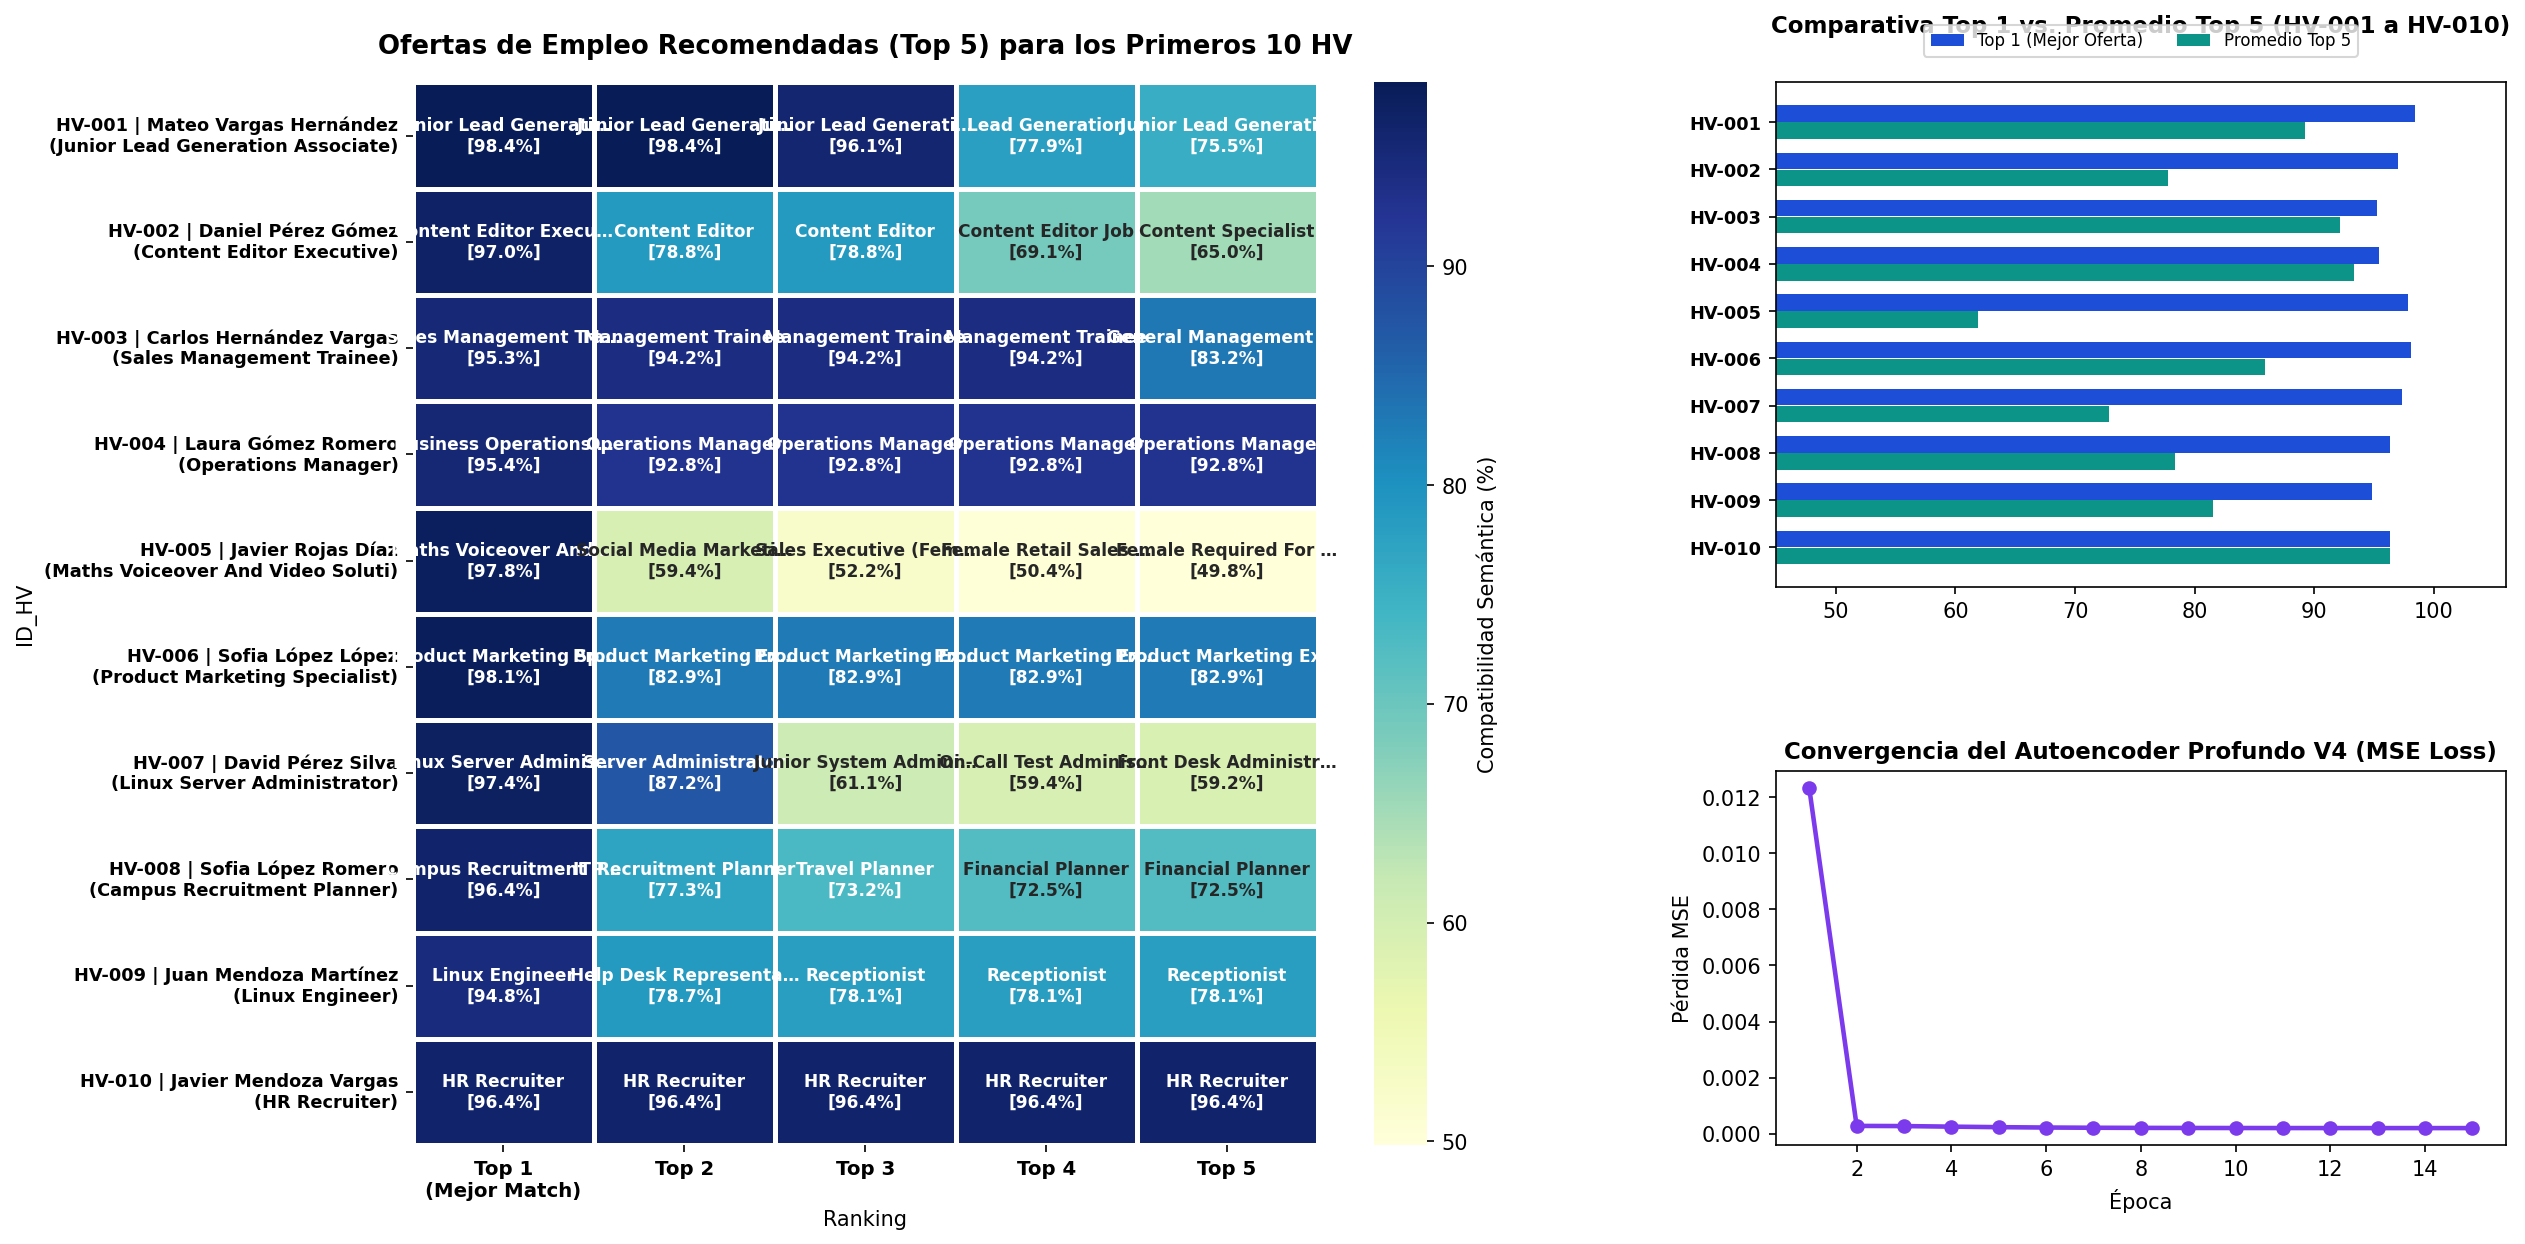

interactive(children=(Dropdown(description='Candidato:', layout=Layout(width='650px'), options=(('HV-001 — Mat…

In [6]:
# Visualización de Matriz, Comparativa Top 1 vs Promedio Top 5 y Curva de Pérdida
fig = plt.figure(figsize=(18, 9.2), dpi=150)
gs = fig.add_gridspec(2, 2, width_ratios=[1.55, 1.0], height_ratios=[1.35, 1.0], wspace=0.25, hspace=0.42)

ax_heat = fig.add_subplot(gs[:, 0])
pivot_scores = df_top10.pivot(index='ID_HV', columns='Ranking', values='Compatibilidad (%)')
pivot_jobs = df_top10.pivot(index='ID_HV', columns='Ranking', values='Cargo_Recomendado')
y_labels = [f"{r['ID_HV']} | {r['Candidato']}\n({r['Perfil_Candidato'][:32]})" for _, r in df_top10.drop_duplicates('ID_HV').iterrows()]

annot_matrix = np.empty(pivot_scores.shape, dtype=object)
for r in range(pivot_scores.shape[0]):
    for c in range(pivot_scores.shape[1]):
        job_str = str(pivot_jobs.iloc[r, c])
        job_str = (job_str[:20] + "…") if len(job_str) > 22 else job_str
        annot_matrix[r, c] = f"{job_str}\n[{pivot_scores.iloc[r, c]:.1f}%]"

sns.heatmap(pivot_scores, annot=annot_matrix, fmt='', cmap='YlGnBu', cbar_kws={'label': 'Compatibilidad Semántica (%)'},
            linewidths=1.5, linecolor='white', annot_kws={'size': 8.2, 'weight': 'bold'}, ax=ax_heat)
ax_heat.set_yticklabels(y_labels, rotation=0, fontsize=8.5, fontweight='bold')
ax_heat.set_xticklabels(['Top 1\n(Mejor Match)', 'Top 2', 'Top 3', 'Top 4', 'Top 5'], fontsize=9.5, fontweight='bold')
ax_heat.set_title('Ofertas de Empleo Recomendadas (Top 5) para los Primeros 10 HV', fontsize=12.5, fontweight='bold', pad=14)

ax_bar = fig.add_subplot(gs[0, 1])
summary_10 = df_top10.groupby(['ID_HV', 'Candidato'], as_index=False).agg(Top1=('Compatibilidad (%)', 'max'), Prom_Top5=('Compatibilidad (%)', 'mean'))
y_pos = np.arange(len(summary_10))
ax_bar.barh(y_pos - 0.18, summary_10['Top1'], height=0.35, color='#1D4ED8', label='Top 1 (Mejor Oferta)')
ax_bar.barh(y_pos + 0.18, summary_10['Prom_Top5'], height=0.35, color='#0D9488', label='Promedio Top 5')
ax_bar.set_yticks(y_pos)
ax_bar.set_yticklabels(summary_10['ID_HV'], fontsize=8.5, fontweight='bold')
ax_bar.invert_yaxis()
ax_bar.set_xlim(45, 106)
ax_bar.set_title('Comparativa Top 1 vs. Promedio Top 5 (HV-001 a HV-010)', fontsize=11, fontweight='bold', pad=24)
ax_bar.legend(loc='upper center', bbox_to_anchor=(0.5, 1.13), ncol=2, fontsize=8)

ax_loss = fig.add_subplot(gs[1, 1])
ax_loss.plot(np.arange(1, len(loss_history) + 1), loss_history, marker='o', color='#7C3AED', linewidth=2.2)
ax_loss.set_title('Convergencia del Autoencoder Profundo V4 (MSE Loss)', fontsize=11, fontweight='bold')
ax_loss.set_xlabel('Época')
ax_loss.set_ylabel('Pérdida MSE')
plt.tight_layout()
plt.savefig('visualizacion_top10_hvs_ux.png', bbox_inches='tight', dpi=150)
plt.show()

# Explorador Interactivo UX (ipywidgets) para consultar cualquiera de los 300 candidatos
try:
    import ipywidgets as widgets
    opciones_hv = [(f"{r['ID_HV']} — {r['Candidato']} ({r['Perfil_Profesional']})", idx) for idx, r in df_results_300.iterrows()]
    selector = widgets.Dropdown(options=opciones_hv, value=0, description='Candidato:', layout=widgets.Layout(width='650px'))
    def ver_candidato(idx):
        row = df_results_300.iloc[idx]
        data_rows = []
        for k in range(1, 6):
            data_rows.append({
                'Ranking': f'Top {k}',
                'Cargo Recomendado': row[f'Top {k} - Cargo'],
                'Empresa': row[f'Top {k} - Empresa'],
                'Ubicación': row[f'Top {k} - Ubicación'],
                'Compatibilidad (%)': row[f'Top {k} - Compatibilidad (%)']
            })
        display(pd.DataFrame(data_rows))
    widgets.interact(ver_candidato, idx=selector)
except Exception as e:
    print("Modo estático activo (ipywidgets opcional):", e)
